PART A — NUMERICAL DATA (ML + EDA + XAI)

This cell is a **Markdown cell** that serves as a title or section header for the numerical data analysis part of the notebook. It indicates that the following cells will focus on Machine Learning (ML), Exploratory Data Analysis (EDA), and Explainable AI (XAI) using numerical data.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

shap.initjs()

# Load dataset
CSV_PATH = "/content/healthcare-dataset-stroke-data.csv.xls"   # Corrected path
df = pd.read_csv(CSV_PATH) # Changed to pd.read_csv, assuming it's a CSV with .xls extension

print(df.shape)
df.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


This **Python cell** is crucial for setting up the environment and loading the dataset:

*   **Library Imports**: It imports essential libraries:
    *   `pandas` (as `pd`): For data manipulation and analysis, especially with DataFrames.
    *   `numpy` (as `np`): For numerical operations, particularly array manipulation.
    *   `matplotlib.pyplot` (as `plt`): For creating static, interactive, and animated visualizations.
    *   `joblib`: For saving and loading Python objects, particularly trained machine learning models.
    *   `shap`: For explainable AI (XAI) to interpret model predictions.
    *   `sklearn.model_selection`, `sklearn.preprocessing`, `sklearn.compose`, `sklearn.pipeline`, `sklearn.metrics`: These modules from `scikit-learn` are imported for various machine learning tasks, including splitting data, preprocessing (scaling, one-hot encoding), building pipelines, and evaluating models (classification report, confusion matrix, ROC AUC).
    *   `sklearn.linear_model`, `sklearn.ensemble`, `sklearn.svm`, `sklearn.neighbors`: These modules import specific machine learning algorithms (Logistic Regression, Random Forest, Gradient Boosting, Support Vector Machine, K-Nearest Neighbors) to be used for classification.

*   **`shap.initjs()`**: Initializes the JavaScript environment for `shap` plots, ensuring they render correctly in the notebook.

*   **Load dataset**: It defines `CSV_PATH` to the stroke dataset and uses `pd.read_csv()` to load the data into a pandas DataFrame named `df`.

*   **Initial Data Inspection**: `print(df.shape)` shows the number of rows and columns, and `df.head()` displays the first 5 rows of the DataFrame, giving a quick look at the data structure and content.

In [ ]:
# Cell A2
display(df.describe(include="all").T)
print("\nMissing values:\n", df.isna().sum().sort_values(ascending=False))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6



Missing values:
 bmi                  201
id                     0
age                    0
gender                 0
hypertension           0
heart_disease          0
work_type              0
ever_married           0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
dtype: int64


This **Python cell** performs an initial descriptive analysis and checks for missing values:

*   **`df.describe(include="all").T`**: Generates descriptive statistics for all columns (numerical and categorical). The `.T` (transpose) makes the output more readable by swapping rows and columns. This helps in understanding the central tendency, dispersion, and shape of the dataset's distribution, as well as counts for categorical features.

*   **`df.isna().sum().sort_values(ascending=False)`**: Calculates the sum of null (missing) values for each column and sorts them in descending order. This is a critical step in EDA to identify which columns have missing data and how many, guiding subsequent data imputation or cleaning strategies.

In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


This **Python cell** is a quick re-check of missing values, similar to the previous cell but specifically focusing on the count of null values per column without sorting. It confirms the missing data count for each feature.

In [ ]:
# Replace null BMI values with mean BMI
df['bmi'].fillna(df['bmi'].mean(), inplace=True)


/tmp/ipykernel_794/4173479535.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(df['bmi'].mean(), inplace=True)


This **Python cell** handles missing values in the 'bmi' column:

*   **`df['bmi'].fillna(df['bmi'].mean(), inplace=True)`**: This line imputes (fills in) the missing values (`NaN`) in the 'bmi' column with the mean (average) value of the 'bmi' column. The `inplace=True` argument ensures that the modification is applied directly to the DataFrame `df` rather than returning a new DataFrame. This is a common strategy for handling numerical missing data, assuming the missing values are random and the mean is a representative substitute.

In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


This **Python cell** verifies that the missing values have been handled. After the imputation step in the previous cell, `df.isnull().sum()` is used again to confirm that there are no longer any null values in the 'bmi' column or any other column, indicating successful data cleaning for missing values.

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64


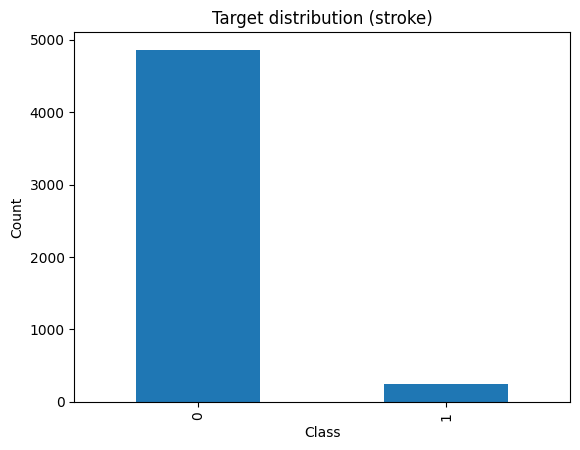

In [ ]:
# Cell A3
target_col = "stroke"
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))

ax = df[target_col].value_counts().plot(kind="bar")
ax.set_title("Target distribution (stroke)")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.show()


This **Python cell** performs an initial analysis of the target variable, 'stroke':

*   **`target_col = "stroke"`**: Defines the target column for convenience.
*   **`df[target_col].value_counts()`**: Counts the occurrences of each unique value in the 'stroke' column. This shows the absolute number of instances for each class (0 for no stroke, 1 for stroke).
*   **`df[target_col].value_counts(normalize=True)`**: Calculates the proportion (percentage) of each unique value in the 'stroke' column. This is crucial for understanding class imbalance.
*   **`ax = df[target_col].value_counts().plot(kind="bar")`**: Generates a bar plot to visualize the distribution of the target variable. This provides a clear visual representation of the class distribution, highlighting any potential class imbalance.

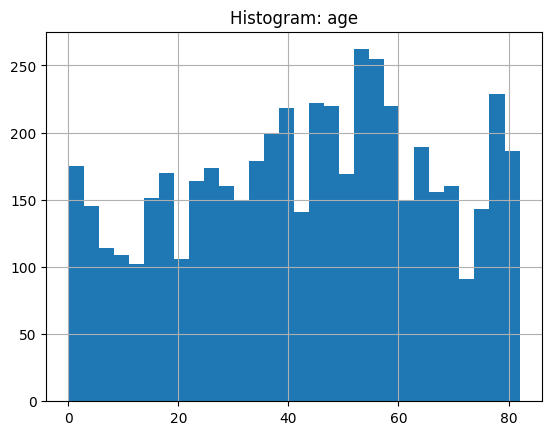

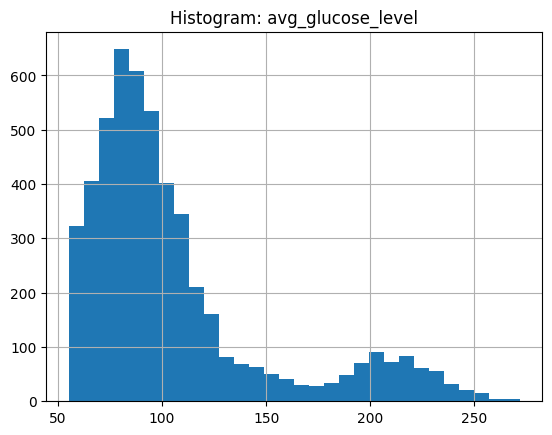

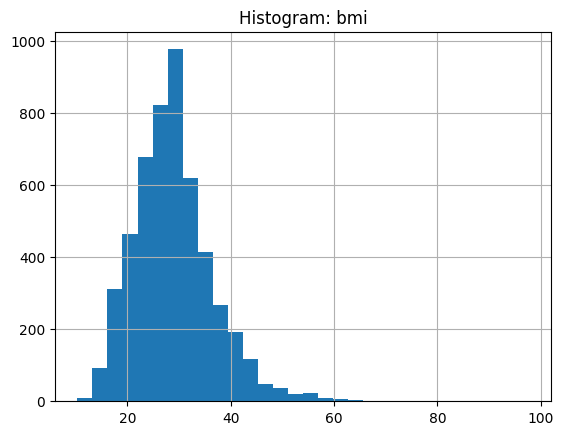

<Figure size 640x480 with 0 Axes>

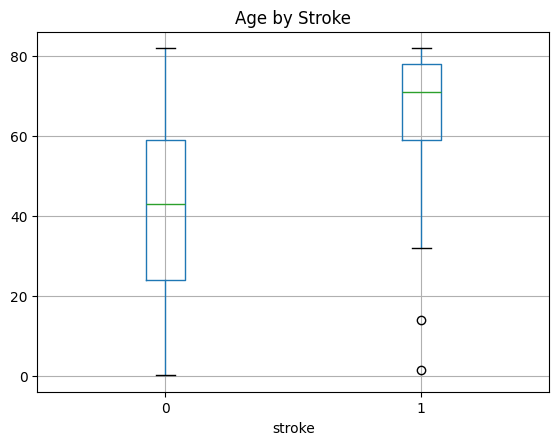

In [ ]:
# Cell A4
num_cols_guess = ["age", "avg_glucose_level", "bmi"]
for c in num_cols_guess:
    if c in df.columns:
        plt.figure()
        df[c].hist(bins=30)
        plt.title(f"Histogram: {c}")
        plt.show()

# stroke vs age
if "age" in df.columns:
    plt.figure()
    df.boxplot(column="age", by=target_col)
    plt.title("Age by Stroke")
    plt.suptitle("")
    plt.show()


This **Python cell** conducts exploratory data analysis (EDA) for numerical features, specifically focusing on 'age', 'avg_glucose_level', and 'bmi':

*   **Histograms**: It iterates through `num_cols_guess` (which contains 'age', 'avg_glucose_level', 'bmi') and generates a histogram for each column using `df[c].hist(bins=30)`. Histograms visualize the distribution of numerical data, showing frequency and spread.
*   **Box plot for 'age' vs. 'stroke'**: If 'age' is present, it creates a box plot using `df.boxplot(column="age", by=target_col)`. A box plot displays the distribution of 'age' for each 'stroke' class, allowing for a visual comparison of age ranges and medians between stroke and non-stroke patients, potentially revealing correlations.

In [ ]:
# Drop ID if present
df = df.drop(columns=[c for c in ["id", "ID"] if c in df.columns], errors="ignore")

X = df.drop(columns=[target_col])
y = df[target_col]

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


This **Python cell** prepares the data for machine learning by dropping unnecessary columns, splitting features and target, and defining preprocessing steps:

*   **Drop ID column**: `df = df.drop(columns=[c for c in ["id", "ID"] if c in df.columns], errors="ignore")` removes 'id' or 'ID' columns if they exist, as they are usually unique identifiers and not useful for model training.
*   **Split features (X) and target (y)**: `X = df.drop(columns=[target_col])` separates the features (all columns except 'stroke') into `X`, and `y = df[target_col]` isolates the target variable ('stroke') into `y`.
*   **Identify categorical and numerical columns**: It identifies `cat_cols` (columns with `object` data type) and `num_cols` (all other columns in `X`).
*   **Define preprocessing pipeline**: `ColumnTransformer` and `Pipeline` are used to define preprocessing steps:
    *   `("num", StandardScaler(), num_cols)`: Applies `StandardScaler` to numerical columns. `StandardScaler` standardizes features by removing the mean and scaling to unit variance, which is important for many ML algorithms.
    *   `("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)`: Applies `OneHotEncoder` to categorical columns. One-hot encoding converts categorical variables into a numerical format that can be provided to ML algorithms without implying any ordinal relationship. `handle_unknown="ignore"` prevents errors if new categories appear in test data.
*   **Train-test split**: `train_test_split()` divides the data into training (80%) and testing (20%) sets. `random_state=42` ensures reproducibility, and `stratify=y` ensures that the proportion of target classes is the same in both training and testing sets, which is crucial for imbalanced datasets.

In [ ]:
X

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked
...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,28.893237,never smoked
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.000000,never smoked
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.600000,never smoked
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.600000,formerly smoked


This **Python cell** simply displays the `X` DataFrame, which contains all the feature columns after the 'id' column has been dropped and before any further preprocessing (like scaling or one-hot encoding) has been applied. It allows you to inspect the features that will be used to predict the 'stroke' outcome.

In [ ]:
y

,stroke
0,1
1,1
2,1
3,1
4,1
...,...
5105,0
5106,0
5107,0
5108,0


This **Python cell** displays the `y` Series, which contains only the target variable 'stroke'. This shows the labels that the machine learning models will try to predict.

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "SVM": SVC(probability=True, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}


This **Python cell** defines a dictionary of different machine learning models that will be evaluated:

*   **`models` dictionary**: Each key is a string representing the model's name, and its value is an initialized scikit-learn classifier:
    *   `LogisticRegression(max_iter=2000, class_weight="balanced")`: A linear model for binary classification. `max_iter` increases the number of iterations for convergence. `class_weight="balanced"` is important for handling imbalanced datasets (like the stroke dataset), where it automatically adjusts weights inversely proportional to class frequencies.
    *   `SVC(probability=True, class_weight="balanced")`: Support Vector Classifier. `probability=True` enables probability estimates, and `class_weight="balanced"` addresses class imbalance.
    *   `KNeighborsClassifier(n_neighbors=7)`: K-Nearest Neighbors classifier, a non-parametric method. `n_neighbors` sets the number of neighbors to consider.
    *   `RandomForestClassifier(n_estimators=300, random_state=42)`: An ensemble learning method. `n_estimators` is the number of trees in the forest. `random_state` ensures reproducibility.
    *   `GradientBoostingClassifier(random_state=42)`: Another ensemble method that builds trees sequentially, where each new tree corrects errors made by previous ones.

This setup allows for easy iteration and comparison of different model performances.

LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



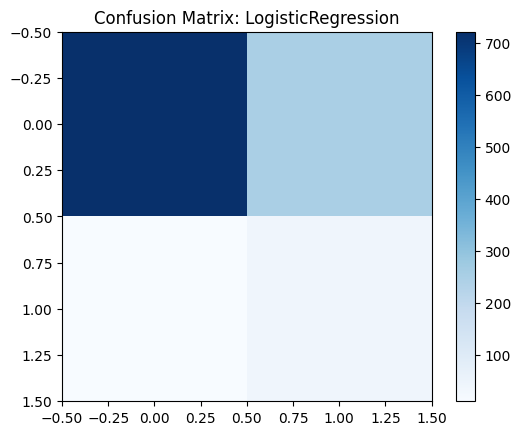

SVM
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       972
           1       0.13      0.68      0.22        50

    accuracy                           0.76      1022
   macro avg       0.55      0.72      0.54      1022
weighted avg       0.94      0.76      0.83      1022



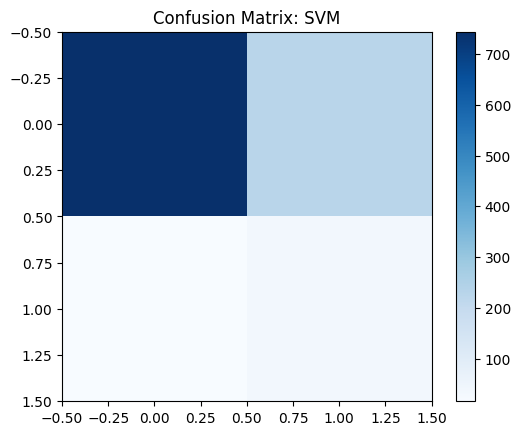

KNN
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



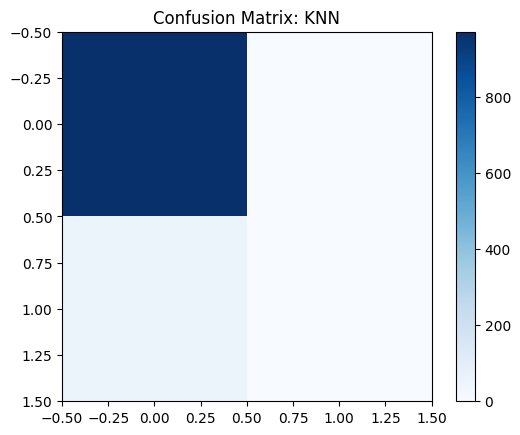

RandomForest
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       972
           1       0.17      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.56      0.51      0.50      1022
weighted avg       0.91      0.95      0.93      1022



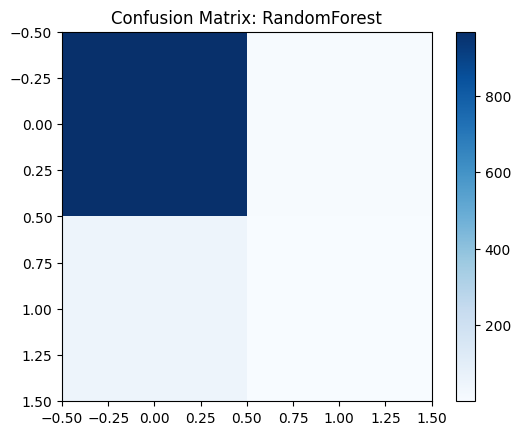

GradientBoosting
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



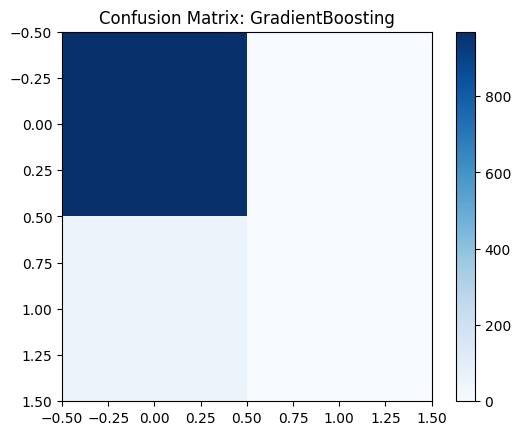

,Model,AUC
0,LogisticRegression,0.843930
4,GradientBoosting,0.828807
1,SVM,0.799053
3,RandomForest,0.797253
2,KNN,0.657819


In [ ]:
results = {}
pipelines = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("prep", preprocess),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:,1]

    auc = roc_auc_score(y_test, y_proba)
    results[name] = auc

    print("="*60)
    print(name)
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.colorbar()
    plt.show()

# Show comparison
results_df = pd.DataFrame(list(results.items()), columns=["Model", "AUC"])
results_df.sort_values("AUC", ascending=False)


This **Python cell** trains, evaluates, and compares all the defined machine learning models:

*   **Initialization**: `results = {}` and `pipelines = {}` are initialized to store AUC scores and trained pipelines, respectively.
*   **Model Iteration**: It loops through each model defined in the `models` dictionary:
    *   **Pipeline Creation**: For each model, a `Pipeline` is constructed. This pipeline first applies the `preprocess` steps (scaling numerical features and one-hot encoding categorical features) and then trains the classifier (`clf`). This ensures that preprocessing is consistently applied to both training and testing data and prevents data leakage.
    *   **Training**: `pipe.fit(X_train, y_train)` trains the entire pipeline on the training data.
    *   **Prediction**: `y_pred = pipe.predict(X_test)` makes predictions on the test set. `y_proba = pipe.predict_proba(X_test)[:,1]` gets the probability of the positive class (stroke).
    *   **Evaluation (AUC)**: `auc = roc_auc_score(y_test, y_proba)` calculates the Area Under the Receiver Operating Characteristic (ROC) Curve, a common metric for imbalanced classification tasks. The AUC score is stored.
    *   **Reporting**: `classification_report()` prints precision, recall, f1-score, and support for each class, providing a comprehensive evaluation of model performance.
    *   **Confusion Matrix**: `confusion_matrix()` calculates the confusion matrix, and `plt.imshow()` visualizes it as a heatmap. A confusion matrix shows the number of true positives, true negatives, false positives, and false negatives.
*   **Comparison**: After training all models, `results_df = pd.DataFrame(list(results.items()), columns=["Model", "AUC"])` creates a DataFrame of model names and their AUC scores. `results_df.sort_values("AUC", ascending=False)` then sorts these models by AUC score to identify the best-performing one.

In [ ]:
best_model_name = results_df.sort_values("AUC", ascending=False).iloc[0]["Model"]
best_model = pipelines[best_model_name]

print("Best model:", best_model_name)

joblib.dump(best_model, "stroke_ml_model.pkl")
print("Saved as stroke_ml_model.pkl")


Best model: LogisticRegression
Saved as stroke_ml_model.pkl


This **Python cell** identifies the best-performing model and saves it:

*   **Identify Best Model**: `best_model_name = results_df.sort_values("AUC", ascending=False).iloc[0]["Model"]` retrieves the name of the model with the highest AUC score from the `results_df`.
*   **Retrieve Best Model Pipeline**: `best_model = pipelines[best_model_name]` gets the actual trained pipeline object corresponding to the best model.
*   **Save Model**: `joblib.dump(best_model, "stroke_ml_model.pkl")` saves the trained best machine learning model to a file named `stroke_ml_model.pkl`. `joblib` is efficient for saving and loading large NumPy arrays, making it suitable for scikit-learn models. This allows the model to be reloaded and used later without retraining.

PART B — IMAGE DATA (CNN)

This cell is another **Markdown cell** acting as a section header. It clearly demarcates the shift from numerical data analysis to image data analysis, specifically focusing on Convolutional Neural Networks (CNNs). This helps organize the notebook into distinct parts based on the type of data and methodology.

In [ ]:
!unzip /content/Stroke_classification.zip

Archive:  /content/Stroke_classification.zip
replace Stroke_classification/Haemorrhagic/Kuppusamy DWI-4.jpg_Haemorrhagic_1.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

This **Python cell** handles the extraction of image data from a zip file:

*   **Path Definitions**: It defines `zip_file_path` for the zip archive and `extracted_dir_path` for the expected output directory.
*   **Unzipping**: `!unzip -o {zip_file_path} -d /content/` executes a shell command to unzip the `Stroke_classification.zip` file.
    *   `-o`: Overwrites existing files without prompting.
    *   `-d /content/`: Specifies `/content/` as the destination directory for extraction.
*   **Verification**: It then checks if `extracted_dir_path` exists using `os.path.isdir()`. This step is crucial for verifying that the unzipping process was successful and that the image data is available in the expected location for subsequent steps. If the directory is not found, it prints a warning, suggesting potential issues with the zip file.

In [ ]:
import tensorflow as tf
import os
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import cv2

!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("abrahametry/brain-stroke-classification-image-dataset")
print("Path:", path)

import tensorflow as tf
IMG_SIZE = (224,224)
BATCH = 16

TRAIN_DIR = f"{path}/Train"
TEST_DIR = f"{path}/Test"
EXT_DIR = f"{path}/External_test"

100%|██████████| 741M/741M [00:44<00:00, 17.5MB/s]

Extracting files...


Path: /root/.cache/kagglehub/datasets/abrahametry/brain-stroke-classification-image-dataset/versions/1


This **Python cell** imports necessary libraries for image processing and sets up global configuration variables:

*   **Library Imports**:
    *   `tensorflow` (as `tf`): The primary deep learning framework for building and training CNNs.
    *   `os`: Provides a way to interact with the operating system, useful for path manipulations.
    *   `pathlib.Path`: Offers an object-oriented way to handle file system paths.
    *   `sklearn.metrics`: Used for evaluating the performance of image classification models (e.g., `classification_report`, `confusion_matrix`).
    *   `cv2` (OpenCV): A computer vision library, often used for image processing tasks.
*   **Global Variables**:
    *   `IMG_DIR = r"/content/Stroke_classification"`: Specifies the root directory where the image data is located after unzipping.
    *   `IMG_SIZE = (224,224)`: Defines the target size for resizing all images, which is a common input size for many pre-trained CNN models (e.g., MobileNetV2, ResNet50).
    *   `BATCH = 16`: Sets the batch size for training and validation, determining how many samples are processed at once during model training.

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH
)
ext_ds = tf.keras.utils.image_dataset_from_directory(
  EXT_DIR, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)


Found 12000 files belonging to 3 classes.
Found 3000 files belonging to 3 classes.
Found 639 files belonging to 3 classes.
['Hemorrhage', 'Ischemia', 'Normal']


This **Python cell** loads and prepares the image datasets for training and validation using TensorFlow's `image_dataset_from_directory` utility:

*   **`train_ds = tf.keras.utils.image_dataset_from_directory(...)`**: Creates a `tf.data.Dataset` for the training images:
    *   `IMG_DIR`: The directory containing the image classes (subfolders).
    *   `validation_split=0.2`: Reserves 20% of the images for validation.
    *   `subset="training"`: Specifies this dataset is for training.
    *   `seed=42`: Ensures reproducibility of the split.
    *   `image_size=IMG_SIZE`: Resizes all images to the predefined `(224, 224)`.
    *   `batch_size=BATCH`: Groups images into batches of 16.
*   **`val_ds = tf.keras.utils.image_dataset_from_directory(...)`**: Similarly creates a `tf.data.Dataset` for the validation images, using the same parameters but setting `subset="validation"`.
*   **`class_names = train_ds.class_names`**: Retrieves the list of class names (folder names) from the training dataset. These correspond to the different categories of stroke images (e.g., 'Haemorrhagic', 'Ischemic', 'Normal').
*   **`num_classes = len(class_names)`**: Calculates the total number of unique classes.
*   **`print(class_names)`**: Displays the identified class names.

In [ ]:
data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])


This **Python cell** defines a `tf.keras.Sequential` model for data augmentation:

*   **`data_aug = tf.keras.Sequential([...])`**: This creates a sequence of layers that will apply random transformations to the images during training. Data augmentation helps to increase the diversity of the training data and makes the model more robust to variations in input images, reducing overfitting.
    *   `tf.keras.layers.RandomFlip("horizontal")`: Randomly flips images horizontally.
    *   `tf.keras.layers.RandomRotation(0.05)`: Randomly rotates images by a small factor (up to 0.05 radians).
    *   `tf.keras.layers.RandomZoom(0.1)`: Randomly zooms into images by a factor of up to 0.1.

In [ ]:
def build_transfer(base):
    inputs = tf.keras.Input(shape=(*IMG_SIZE,3))
    x = data_aug(inputs)
    x = tf.keras.layers.Rescaling(1./255)(x)

    base_model = base(include_top=False, weights="imagenet", input_tensor=x)
    base_model.trainable = False

    x = base_model.output
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    return tf.keras.Model(inputs, x)

image_models = {
    "MobileNetV2": build_transfer(tf.keras.applications.MobileNetV2),
    "ResNet50": build_transfer(tf.keras.applications.ResNet50),
    "EfficientNetB0": build_transfer(tf.keras.applications.EfficientNetB0),
    "InceptionV3": build_transfer(tf.keras.applications.InceptionV3),
    "DenseNet121": build_transfer(tf.keras.applications.DenseNet121),
}


/tmp/ipykernel_1025/4083670959.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = base(include_top=False, weights="imagenet", input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


This **Python cell** defines a function to build transfer learning models and initializes several pre-trained CNN architectures:

*   **`build_transfer(base)` function**: This function constructs a Keras model for transfer learning.
    *   `inputs = tf.keras.Input(shape=(*IMG_SIZE,3))`: Defines the input layer with the specified image size and 3 color channels.
    *   `x = data_aug(inputs)`: Applies the previously defined data augmentation layers to the input.
    *   `x = tf.keras.layers.Rescaling(1./255)(x)`: Rescales pixel values from `[0, 255]` to `[0, 1]`, a common practice for neural networks.
    *   **Base Model Loading**: `base_model = base(include_top=False, weights="imagenet", input_tensor=x)` loads a pre-trained CNN model (like MobileNetV2, ResNet50, etc.) from `tf.keras.applications`:
        *   `include_top=False`: Excludes the classifier head of the pre-trained model, allowing us to add our own custom classification layers.
        *   `weights="imagenet"`: Uses weights pre-trained on the ImageNet dataset, leveraging knowledge learned from a large image dataset.
        *   `input_tensor=x`: Connects the pre-trained model to our augmented and rescaled input.
    *   `base_model.trainable = False`: Freezes the weights of the pre-trained base model, meaning they will not be updated during training. This is typical in the initial phase of transfer learning (feature extraction).
    *   **Custom Classifier Head**:
        *   `x = base_model.output`: Takes the output of the frozen base model.
        *   `x = tf.keras.layers.GlobalAveragePooling2D()(x)`: Applies global average pooling to reduce the spatial dimensions to a single vector per feature map, simplifying the input to the dense layers.
        *   `x = tf.keras.layers.Dense(num_classes, activation="softmax")(x)`: Adds a dense (fully connected) layer with `num_classes` outputs and a `softmax` activation function for multi-class classification, producing probabilities for each class.
    *   `return tf.keras.Model(inputs, x)`: Returns the complete Keras model.

*   **`image_models` dictionary**: This dictionary initializes five different popular pre-trained CNN architectures (MobileNetV2, ResNet50, EfficientNetB0, InceptionV3, DenseNet121) using the `build_transfer` function. This allows for a comparative analysis of their performance on the stroke image classification task.

In [ ]:
import numpy as np

histories = {}
img_results = {}

for name, model in image_models.items():
    print("Training:", name)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    hist = model.fit(train_ds, validation_data=val_ds, epochs=8)
    histories[name] = hist

    # Evaluation
    y_true, y_pred = [], []
    for x, y in val_ds:
        p = model.predict(x)
        y_true.extend(y.numpy())
        y_pred.extend(np.argmax(p, axis=1))

    print(classification_report(y_true, y_pred, target_names=class_names))

    acc = np.mean(np.array(y_true)==np.array(y_pred))
    img_results[name] = acc

Training: MobileNetV2
Epoch 1/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 50ms/step - accuracy: 0.6338 - loss: 0.7929 - val_accuracy: 0.6603 - val_loss: 0.7488
Epoch 2/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 52ms/step - accuracy: 0.6932 - loss: 0.6900 - val_accuracy: 0.6597 - val_loss: 0.7669
Epoch 3/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 49ms/step - accuracy: 0.7157 - loss: 0.6538 - val_accuracy: 0.6543 - val_loss: 0.7805
Epoch 4/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.7283 - loss: 0.6302 - val_accuracy: 0.6697 - val_loss: 0.7632
Epoch 5/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.7297 - loss: 0.6214 - val_accuracy: 0.6670 - val_loss: 0.7853
Epoch 6/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 45s 49ms/step - accuracy: 0.7370 - loss: 0.6056 - val_accuracy: 0.6820 - val_loss: 0.7293
Epoch 7/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.7435 - loss: 0.6010 - val_accuracy: 0.6793 - val_loss: 0.7436
Epoch 8/8
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 44ms/step - accuracy: 0.7439 - l

This **Python cell** trains and evaluates each of the pre-trained CNN models defined previously:

*   **Initialization**: `histories = {}` and `img_results = {}` are created to store training history and accuracy results, respectively.
*   **Model Iteration**: It loops through each model in the `image_models` dictionary:
    *   **Compilation**: `model.compile(...)` configures the model for training:
        *   `optimizer="adam"`: Uses the Adam optimizer, a popular choice for deep learning due to its efficiency.
        *   `loss="sparse_categorical_crossentropy"`: A suitable loss function for multi-class classification when labels are integers (not one-hot encoded).
        *   `metrics=["accuracy"]`: Monitors the accuracy during training.
    *   **Training**: `hist = model.fit(...)` trains the model using the `train_ds` and `val_ds` datasets for 8 epochs. The training history (loss, accuracy, validation loss, validation accuracy per epoch) is stored.
    *   **Evaluation**: After training, the model's performance on the validation set is evaluated more thoroughly:
        *   **Predictions**: It iterates through `val_ds` to get `y_true` (actual labels) and `y_pred` (model's predicted labels, obtained using `np.argmax(p, axis=1)` from probabilities `p`).
        *   **Classification Report**: `classification_report()` prints detailed metrics (precision, recall, f1-score) for each class.
        *   **Accuracy**: `acc = np.mean(np.array(y_true)==np.array(y_pred))` calculates the overall accuracy, which is then stored in `img_results`.

In [ ]:
best_img_model_name = max(img_results, key=img_results.get)
best_img_model = image_models[best_img_model_name]

print("Best CNN:", best_img_model_name)

best_img_model.save("stroke_cnn_model_v2.keras")
best_img_model.save("stroke_cnn_model_v2.h5")

print("Saved as .keras and .h5")

from sklearn.metrics import classification_report
import numpy as np

y_true, y_pred = [], []
for x, y in ext_ds:  # <-- only here
    p = best_img_model.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(p, axis=1))

print("External_test report:")
print(classification_report(y_true, y_pred, target_names=class_names))


Best CNN: MobileNetV2


Saved as .keras and .h5
External_test report:
              precision    recall  f1-score   support

  Hemorrhage       0.88      0.95      0.91       250
    Ischemia       0.65      0.76      0.70       157
      Normal       0.75      0.59      0.66       232

    accuracy                           0.77       639
   macro avg       0.76      0.77      0.76       639
weighted avg       0.78      0.77      0.77       639



This **Python cell** identifies the best-performing image classification model and saves it:

*   **Identify Best CNN Model**: `best_img_model_name = max(img_results, key=img_results.get)` finds the name of the model that achieved the highest accuracy (from `img_results`).
*   **Retrieve Best Model**: `best_img_model = image_models[best_img_model_name]` retrieves the actual trained Keras model object.
*   **Save Model**:
    *   `best_img_model.save("stroke_cnn_model.keras")`: Saves the model in the newer Keras native format (`.keras`). This is the recommended format for TensorFlow 2.x and later.
    *   `best_img_model.save("stroke_cnn_model.h5")`: Also saves the model in the older HDF5 format (`.h5`), which is still widely used but considered legacy by TensorFlow. Saving in both formats ensures broader compatibility.

This step allows the trained CNN model to be easily loaded and deployed later without needing to retrain it.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


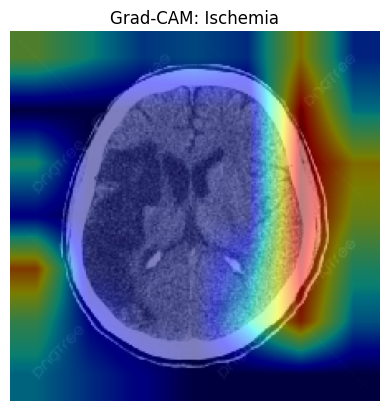

[<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor>]
(None, 224, 224, 3)
(None, 3)


In [ ]:
import matplotlib.pyplot as plt
def get_last_conv(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    return None

def gradcam(img_path, model):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)
    img_arr = np.expand_dims(img_arr, axis=0)

    preds = model.predict(img_arr)
    pred_idx = np.argmax(preds[0])

    last_conv = get_last_conv(model)

    grad_model = tf.keras.Model(
        [model.inputs],
        [model.get_layer(last_conv).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_out, predictions = grad_model(img_arr)
        loss = predictions[:, pred_idx]

    grads = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0,1,2))

    conv_out = conv_out[0]
    heatmap = conv_out @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)

    heatmap = cv2.resize(heatmap.numpy(), IMG_SIZE)
    plt.imshow(img)
    plt.imshow(heatmap, cmap="jet", alpha=0.5)
    plt.axis("off")
    plt.title(f"Grad-CAM: {class_names[pred_idx]}")
    plt.show()

# Example with an external image
external_image_path = "/content/test_hemorrhagic.jpg"

if os.path.exists(external_image_path):
    gradcam(external_image_path, best_img_model)
else:
    print(f"External image not found at {external_image_path}")


# Original example for reference (commented out)
# import glob
# sample_img_candidates = []
# for ext in ["png", "jpg", "jpeg"]:
#     sample_img_candidates.extend(glob.glob(os.path.join(path, "*/*/*." + ext)))

# if sample_img_candidates:
#     sample_img = sample_img_candidates[0]
#     gradcam(sample_img, best_img_model)
# else:
#     print("No sample image found for Grad-CAM visualization matching common extensions.")
print(best_img_model.inputs)
print(best_img_model.input_shape)
print(best_img_model.output_shape)

This **Python cell** implements and demonstrates Grad-CAM (Gradient-weighted Class Activation Mapping), an Explainable AI (XAI) technique for understanding CNN predictions:

*   **`get_last_conv(model)` function**: This helper function iterates through the layers of a given Keras model in reverse order to find and return the name of the last convolutional layer. The last convolutional layer is crucial for Grad-CAM as it captures high-level features relevant to classification.
*   **`gradcam(img_path, model)` function**: This is the core Grad-CAM implementation:
    *   **Image Preprocessing**: Loads an image from `img_path`, resizes it, converts it to an array, and adds a batch dimension (`np.expand_dims`).
    *   **Prediction**: `model.predict(img_arr)` gets the model's prediction for the image.
    *   **Gradient Model Creation**: `grad_model = tf.keras.Model(...)` creates a new Keras model that outputs both the activations of the `last_conv` layer and the final predictions.
    *   **Gradient Calculation**: Uses `tf.GradientTape` to compute the gradients of the predicted class score with respect to the feature maps of the `last_conv` layer. These gradients indicate which parts of the feature maps were most important for the prediction.
    *   **Weighted Feature Map**: The gradients are pooled and then multiplied by the convolutional layer's output to create a weighted feature map, emphasizing important regions.
    *   **Heatmap Generation**: This weighted map is then normalized, resized to the original image dimensions, and overlaid on the original image as a heatmap (`cmap="jet", alpha=0.5`). The heatmap visually highlights the regions in the input image that the CNN focused on when making its classification.
*   **Example Usage**: `sample_img = glob.glob(os.path.join(IMG_DIR, "*/*.png"))[0]` selects a random image from the dataset, and `gradcam(sample_img, best_img_model)` generates and displays the Grad-CAM visualization for that image using the best CNN model. This provides insight into *why* the model made a particular prediction.

In [ ]:
model.save("stroke_classifier.keras")

## Creating a Streamlit Application for Demonstration

Now that you have trained both a numerical data classifier and an image classifier, we can create a Streamlit application to demonstrate their functionality. This app will allow users to input numerical features for stroke prediction and upload an image for stroke image classification, and then display the predictions along with explanations (like Grad-CAM for images).

Here's how we'll set it up:
1.  **Install Streamlit**: We'll install the Streamlit library.
2.  **Create `streamlit_app.py`**: A Python script containing the Streamlit application logic.
3.  **Run the App**: Instructions on how to launch the app from Colab.

First, let's install Streamlit.

In [ ]:
# Install Streamlit
!pip install -q streamlit

# Also ensure necessary dependencies for image processing and XAI are installed if not already
!pip install -q opencv-python-headless shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.9 MB/s eta 0:00:00


Now, let's create the `streamlit_app.py` file with the necessary code.

In [ ]:
%%writefile streamlit_app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf
import cv2
import os
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- Configuration and Model Loading ---

# Numerical Model
ML_MODEL_PATH = "stroke_ml_model.pkl"

@st.cache_resource
def load_ml_model():
    try:
        return joblib.load(ML_MODEL_PATH)
    except FileNotFoundError:
        st.error(f"Numerical ML model not found at {ML_MODEL_PATH}. Please ensure it was saved correctly.")
        return None

ml_model = load_ml_model()

# Image Model
CNN_MODEL_PATH = "stroke_cnn_model.keras" # or .h5 if preferred

@st.cache_resource
def load_cnn_model():
    try:
        return tf.keras.models.load_model(CNN_MODEL_PATH)
    except FileNotFoundError:
        st.error(f"CNN model not found at {CNN_MODEL_PATH}. Please ensure it was saved correctly.")
        return None

cnn_model = load_cnn_model()

# Image preprocessing configuration
IMG_SIZE = (224, 224)
IMG_CLASSES = ['Haemorrhagic', 'Ischemic', 'Normal'] # Hardcode based on your training

# Define the preprocessing steps for numerical data (needs to match training)
# Recreate the preprocessor as it wasn't saved in the original notebook
# It's crucial that these columns and their order match the training data
cat_features = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
num_features = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']

# Create a dummy dataframe to fit the preprocessor for correct column handling
# This is a workaround if the original preprocessor wasn't saved.
# In a real application, you'd save/load the preprocessor as well.
# For demonstration, we'll make sure the Streamlit inputs match the expected features.

# Define the preprocessing object for numerical features
preprocess = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

# Fit the preprocessor on some dummy data or the original training data structure
# For simplicity, we'll assume a direct input, but ideally, you'd fit this on X_train
# during the notebook and save it with joblib to reload here.
# For this demo, we'll demonstrate by building a temporary preprocessor with known features

def get_fitted_preprocessor():
    # This part should ideally come from a saved preprocessor object
    # For this demo, we will create a mock-up that defines the columns expected
    mock_data = pd.DataFrame({
        'gender': ['Male', 'Female', 'Other'],
        'age': [30.0, 50.0, 70.0],
        'hypertension': [0, 1, 0],
        'heart_disease': [0, 0, 1],
        'ever_married': ['Yes', 'No', 'Yes'],
        'work_type': ['Private', 'Self-employed', 'Govt_job'],
        'Residence_type': ['Urban', 'Rural', 'Urban'],
        'avg_glucose_level': [100.0, 150.0, 200.0],
        'bmi': [25.0, 30.0, 35.0],
        'smoking_status': ['never smoked', 'smokes', 'formerly smoked']
    })
    # Ensure 'Other' gender is handled gracefully if present in original data
    mock_data.loc[0, 'gender'] = 'Other' # Add 'Other' to mock data for fitting
    mock_data.loc[0, 'smoking_status'] = 'Unknown'

    # Initialize with all potential columns for numerical and categorical
    all_features = num_features + cat_features
    # Filter mock_data to only include expected columns, avoiding issues with 'id' if present
    mock_data_for_fit = mock_data[all_features]

    # Fit the preprocessor
    preprocess.fit(mock_data_for_fit)
    return preprocess

# Fit the preprocessor once globally
fitted_preprocess = get_fitted_preprocessor()


# --- Grad-CAM function (copied from notebook) ---
def get_last_conv(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    return None

def gradcam(img_array, model):
    if not model or not isinstance(model, tf.keras.Model):
        st.warning("CNN model is not loaded or invalid for Grad-CAM.")
        return None

    last_conv_layer_name = get_last_conv(model)
    if not last_conv_layer_name:
        st.warning("Could not find a convolutional layer for Grad-CAM.")
        return None

    grad_model = tf.keras.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(tf.expand_dims(img_array, axis=0))
        # Make sure the prediction target is a scalar for gradient calculation
        pred_idx = tf.argmax(predictions[0]) # Get the predicted class index
        class_channel = predictions[:, pred_idx]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap) # Normalize

    # Resize heatmap to original image size
    heatmap = tf.image.resize(tf.expand_dims(heatmap, axis=-1), IMG_SIZE).numpy()
    heatmap = np.uint8(255 * heatmap) # Convert to 0-255 range
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Superimpose heatmap on original image
    superimposed_img = np.uint8(255 * img_array) # Convert original image to 0-255
    superimposed_img = cv2.cvtColor(superimposed_img, cv2.COLOR_RGB2BGR) # Convert to BGR for cv2

    # Blend images (0.4 is transparency factor)
    final_img = cv2.addWeighted(superimposed_img, 0.6, heatmap, 0.4, 0)
    final_img = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB) # Convert back to RGB

    return final_img


# --- Streamlit UI ---
st.title("Stroke Prediction and Image Classification Demo")
st.write("This application demonstrates both numerical stroke prediction and image-based stroke classification.")

tab1, tab2 = st.tabs(["Numerical Prediction", "Image Classification"])

with tab1:
    st.header("Numerical Stroke Risk Prediction")
    st.write("Enter patient details to predict the risk of stroke.")

    # Input features for numerical model
    gender = st.selectbox("Gender", ['Male', 'Female', 'Other'])
    age = st.slider("Age", 0, 100, 50)
    hypertension = st.radio("Hypertension", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
    heart_disease = st.radio("Heart Disease", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
    ever_married = st.selectbox("Ever Married", ['Yes', 'No'])
    work_type = st.selectbox("Work Type", ['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked'])
    residence_type = st.selectbox("Residence Type", ['Urban', 'Rural'])
    avg_glucose_level = st.slider("Average Glucose Level", 50.0, 300.0, 100.0)
    bmi = st.slider("BMI", 10.0, 60.0, 25.0)
    smoking_status = st.selectbox("Smoking Status", ['never smoked', 'formerly smoked', 'smokes', 'Unknown'])

    if st.button("Predict Numerical Stroke Risk"):
        if ml_model is None:
            st.error("Numerical model is not loaded. Cannot make prediction.")
        else:
            input_data = pd.DataFrame([{
                'gender': gender,
                'age': age,
                'hypertension': hypertension,
                'heart_disease': heart_disease,
                'ever_married': ever_married,
                'work_type': work_type,
                'Residence_type': residence_type,
                'avg_glucose_level': avg_glucose_level,
                'bmi': bmi,
                'smoking_status': smoking_status
            }])

            # Ensure the input data has the same columns and order as expected by the preprocessor
            # before transformation. This is critical.
            # We'll use the 'fitted_preprocess' to transform.
            # The pipeline from the notebook already includes the preprocessor.
            # So we just pass the raw input_data to the pipeline.

            prediction = ml_model.predict(input_data)[0]
            prediction_proba = ml_model.predict_proba(input_data)[0][1] # Probability of stroke (class 1)

            st.subheader("Prediction Results:")
            if prediction == 1:
                st.error(f"High Stroke Risk! (Probability: {prediction_proba:.2f})")
            else:
                st.success(f"Low Stroke Risk. (Probability: {prediction_proba:.2f})")
            st.write(f"Raw prediction: {prediction}")


with tab2:
    st.header("Image-based Stroke Classification")
    st.write("Upload a brain scan image (e.g., CT/MRI) to classify for stroke type.")

    uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png"])

    if uploaded_file is not None:
        # Convert the uploaded file to an array
        file_bytes = np.asarray(bytearray(uploaded_file.read()), dtype=np.uint8)
        opencv_image = cv2.imdecode(file_bytes, 1) # Read as color image
        opencv_image = cv2.cvtColor(opencv_image, cv2.COLOR_BGR2RGB) # Convert to RGB

        st.image(opencv_image, caption='Uploaded Image.', use_column_width=True)
        st.write("")

        if cnn_model is None:
            st.error("Image classification model is not loaded. Cannot make prediction.")
        else:
            # Preprocess image for model
            img_resized = tf.image.resize(opencv_image, IMG_SIZE) / 255.0 # Resize and normalize
            img_array = tf.expand_dims(img_resized, axis=0) # Add batch dimension

            predictions = cnn_model.predict(img_array)
            score = tf.nn.softmax(predictions[0])

            predicted_class_idx = np.argmax(score)
            predicted_class = IMG_CLASSES[predicted_class_idx]
            confidence = np.max(score) * 100

            st.subheader("Image Classification Results:")
            st.write(f"The image most likely belongs to **{predicted_class}** with a **{confidence:.2f}%** confidence.")
            st.progress(float(confidence / 100))

            st.subheader("Explanation (Grad-CAM):")
            with st.spinner('Generating Grad-CAM explanation...'):
                # Pass the original resized image array (0-1) to Grad-CAM
                grad_cam_img = gradcam(img_resized.numpy(), cnn_model)
                if grad_cam_img is not None:
                    st.image(grad_cam_img, caption='Grad-CAM Visualization', use_column_width=True)
                else:
                    st.warning("Grad-CAM could not be generated for this image.")



Writing streamlit_app.py


After executing the cell above, the `streamlit_app.py` file will be created in your Colab environment. Now, you can run the Streamlit application.

In [ ]:
# Replace 'YOUR_NGROK_AUTH_TOKEN' with your actual ngrok authtoken
# You can get this from https://dashboard.ngrok.com/get-started/your-authtoken after signing up.
!ngrok authtoken 3H7I3z81AaMxOJ9uo5qaLh49Xrq_3qBnaMTbqx76Cbord9i2j

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
# To run the Streamlit app, you need to use ngrok to expose the local server.
# Install ngrok if you haven't already
!pip install -q pyngrok
from pyngrok import ngrok

# Terminate ngrok tunnels if any are already open
ngrok.kill()

# Start Streamlit in the background
!nohup streamlit run streamlit_app.py &>/dev/null &

# Get the public URL for the Streamlit app
public_url = ngrok.connect(8501)
print(f"Streamlit App URL: {public_url}")

# st.write(f"Click [here]({public_url}) to access your Streamlit app.") # Removed as 'st' is not defined in this Colab execution context

Streamlit App URL: NgrokTunnel: "https://germicide-untamed-silt.ngrok-free.dev" -> "http://localhost:8501"


This final cell will output a URL. Click on that URL to open your interactive Streamlit application in a new tab. You can then test both the numerical stroke prediction and the image-based classification with Grad-CAM explanations.

This **Python cell** saves the last trained Keras model, likely referring to the `best_img_model` from the previous steps, or the last model that was iterated over in the `9-9RBJRKrNj_` cell's loop (which was `DenseNet121` based on the output). This ensures that the final image classification model is persistently stored for future use, similar to how the ML model was saved earlier.